In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
sns.set_theme(style="whitegrid")
df = pd.read_csv('sales_data.csv')
print(df.head())
print(df.info())

   Product_ID   Sale_Date Sales_Rep Region  Sales_Amount  Quantity_Sold  \
0        1052  2023-02-03       Bob  North       5053.97             18   
1        1093  2023-04-21       Bob   West       4384.02             17   
2        1015  2023-09-21     David  South       4631.23             30   
3        1072  2023-08-24       Bob  South       2167.94             39   
4        1061  2023-03-24   Charlie   East       3750.20             13   

  Product_Category  Unit_Cost  Unit_Price Customer_Type  Discount  \
0        Furniture     152.75      267.22     Returning      0.09   
1        Furniture    3816.39     4209.44     Returning      0.11   
2             Food     261.56      371.40     Returning      0.20   
3         Clothing    4330.03     4467.75           New      0.02   
4      Electronics     637.37      692.71           New      0.08   

  Payment_Method Sales_Channel Region_and_Sales_Rep  
0           Cash        Online            North-Bob  
1           Cash        Re

In [ ]:
df['Sale_Date'] = pd.to_datetime(df['Sale_Date'])

df = df.dropna(subset=['Sale_Date', 'Quantity_Sold', 'Unit_Price'])

df['Total_Sales'] = df['Quantity_Sold'] * df['Unit_Price']

df['Month'] = df['Sale_Date'].dt.month
df['Year'] = df['Sale_Date'].dt.year
df['Month_Year'] = df['Sale_Date'].dt.to_period('M')

In [ ]:
product_performance = df.groupby('Product_Category').agg({
    'Quantity_Sold': 'sum',
    'Total_Sales': 'sum'
}).reset_index()

top_products_revenue = product_performance.sort_values(by='Total_Sales', ascending=False)
print(top_products_revenue.head(10))

  Product_Category  Quantity_Sold  Total_Sales
0         Clothing           6922  19286733.93
3        Furniture           6729  18330280.56
1      Electronics           6096  17571040.57
2             Food           5608  15141885.65


In [ ]:

monthly_sales = df.groupby('Month')['Total_Sales'].sum().reset_index()
print(monthly_sales)

timeline_sales = df.groupby('Month_Year')['Total_Sales'].sum().reset_index()
timeline_sales['Month_Year'] = timeline_sales['Month_Year'].astype(str)

    Month  Total_Sales
0       1   7488100.51
1       2   5627477.45
2       3   6008259.41
3       4   5468497.62
4       5   5800626.51
5       6   6142561.23
6       7   4751432.42
7       8   6716190.61
8       9   4557015.58
9      10   6560606.39
10     11   4958930.19
11     12   6250242.79


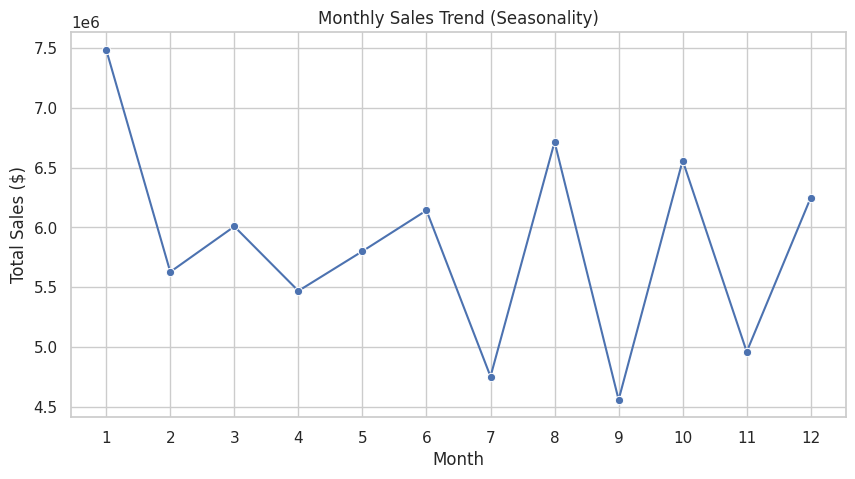

/tmp/ipykernel_3752/773493532.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_10, x='Total_Sales', y='Product_Category', palette='viridis')


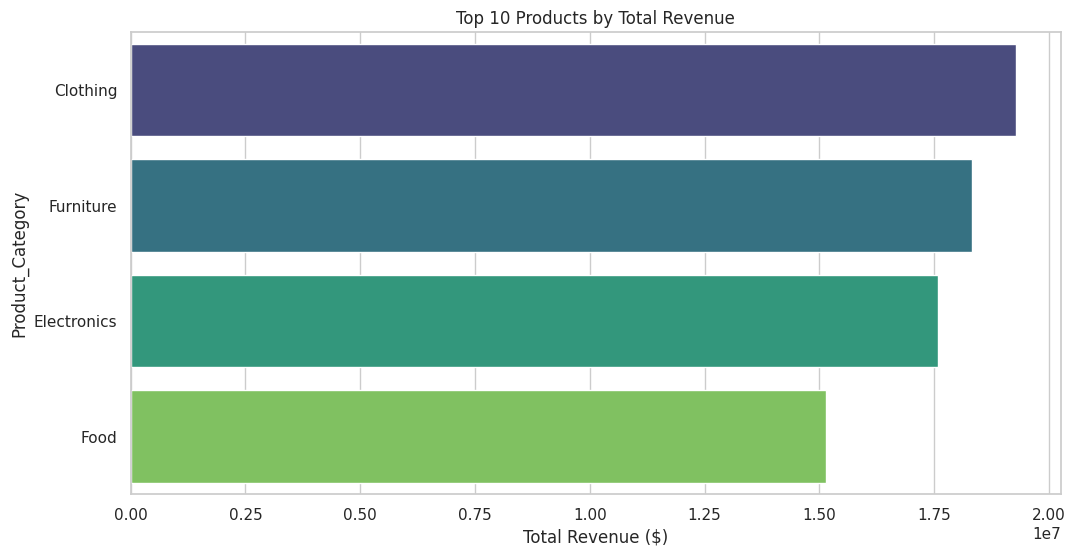

In [ ]:

plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly_sales, x='Month', y='Total_Sales', marker='o', color='b')
plt.title('Monthly Sales Trend (Seasonality)')
plt.xlabel('Month')
plt.ylabel('Total Sales ($)')
plt.xticks(range(1, 13))
plt.show()

plt.figure(figsize=(12, 6))
top_10 = top_products_revenue.head(10)
sns.barplot(data=top_10, x='Total_Sales', y='Product_Category', palette='viridis')
plt.title('Top 10 Products by Total Revenue')
plt.xlabel('Total Revenue ($)')
plt.ylabel('Product_Category')
plt.show()